# Truncated SVD — Low-Rank Approximation Without Centering

## 1. Definition and intuition
Singular Value Decomposition writes a matrix as \(X=U\Sigma V^T\). Truncated SVD keeps only the largest k singular values and their vectors, yielding the best rank-k approximation in Frobenius norm. Unlike standard PCA, scikit-learn's `TruncatedSVD` does not center the input, so it can work directly with sparse matrices such as term-document matrices.

## 2. Mathematics and guarantee
The truncated approximation is \(X_k=U_k\Sigma_kV_k^T\). By the Eckart–Young theorem, it minimizes \(\|X-\tilde X\|_F\) among matrices \(\tilde X\) with rank at most k. The discarded squared singular values sum to the squared reconstruction error for the exact truncated SVD.

This is a matrix approximation guarantee, not a guarantee that the retained directions are best for downstream prediction.

## 3. Assumptions and pitfalls
SVD itself is broadly applicable to finite matrices, but the usefulness of a rank-k approximation depends on the spectrum and task. Since centering is omitted, large means can dominate. For sparse text features, this no-centering behavior is often a feature rather than a bug.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.datasets import make_low_rank_matrix
from sklearn.metrics import mean_squared_error

SEED = 42
rng = np.random.default_rng(SEED)
X = make_low_rank_matrix(n_samples=450, n_features=180, effective_rank=12,
                         tail_strength=0.15, random_state=SEED)
# Shift to nonnegative to mimic count-like data, then compare SVD without centering.
X = X - X.min() + 0.01
print("Matrix shape:", X.shape)


Matrix shape: (450, 180)


## 4. Truncated SVD from scratch

For learning, we use a full NumPy SVD and keep only k directions. This computes more than needed; production use should use randomized or iterative truncated solvers for large matrices.

In [2]:
def truncated_svd_scratch(X, n_components):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or min(X.shape) < 1 or not 1 <= n_components <= min(X.shape):
        raise ValueError("Invalid matrix or n_components")
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    Uk, sk, Vtk = U[:, :n_components], s[:n_components], Vt[:n_components]
    Xk = (Uk * sk) @ Vtk
    return Uk, sk, Vtk, Xk, s

k = 12
U_k, s_k, Vt_k, Xk, singular_values = truncated_svd_scratch(X, k)
print("Top singular values:", np.round(s_k[:5], 2))
print("Reconstruction MSE:", mean_squared_error(X.ravel(), Xk.ravel()))
print("Energy retained:", round(float(np.sum(s_k**2)/np.sum(singular_values**2)), 4))


Top singular values: [19.19  1.    0.99  0.97  0.94]
Reconstruction MSE: 2.467120943074815e-05
Energy retained: 0.9947


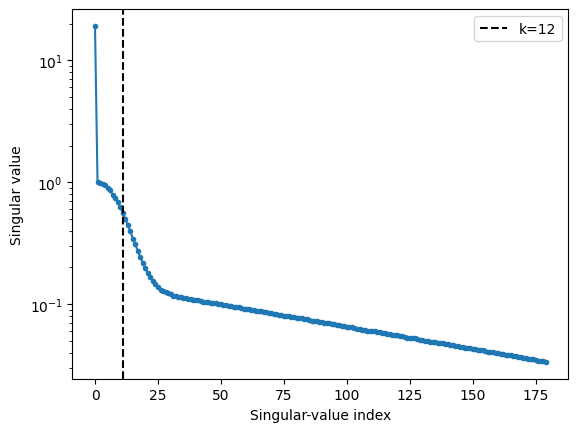

In [3]:
plt.semilogy(singular_values, marker=".")
plt.axvline(k-1, color="black", linestyle="--", label=f"k={k}")
plt.xlabel("Singular-value index"); plt.ylabel("Singular value"); plt.legend(); plt.show()


## 5. Compare with scikit-learn

The randomized solver is approximate. It should produce a good low-rank reconstruction, but not necessarily identical singular vectors to full SVD.

In [4]:
sk_svd = TruncatedSVD(n_components=k, algorithm="randomized", n_iter=7, random_state=SEED)
Z = sk_svd.fit_transform(X)
X_recon = Z @ sk_svd.components_
print("sklearn reconstruction MSE:", mean_squared_error(X.ravel(), X_recon.ravel()))
print("sklearn explained variance ratio sum:", round(float(sk_svd.explained_variance_ratio_.sum()), 4))
assert Z.shape == (X.shape[0], k)
assert X_recon.shape == X.shape and np.isfinite(X_recon).all()


sklearn reconstruction MSE: 2.467120943074815e-05
sklearn explained variance ratio sum: 0.7952


## 6. Hyperparameters and complexity
- `n_components`: chosen low rank.
- `algorithm`: randomized SVD is typically effective for large dense matrices; `arpack` uses an iterative eigensolver.
- `n_iter` / `n_oversamples`: affect randomized approximation quality.
- Dense full SVD is roughly \(O(\min(nd^2,n^2d))\) time. Storage for the input is \(O(nd)\); factors add \(O(nk+kd)\). Sparse matrix solvers can avoid densifying the input.
- For millions of rows, use sparse TF-IDF matrices, randomized/iterative SVD, batch or distributed methods as appropriate. Never call `.toarray()` on a huge sparse matrix without checking memory.
- GPU libraries can speed dense low-rank linear algebra; sparse support and solver quality vary.

## 7. Best practices and checks

Use Truncated SVD for latent semantic analysis and sparse feature reduction; use PCA when centering is desired and memory permits. Choose k based on downstream validation and inspect the singular-value spectrum.

In [5]:
assert np.isfinite(Xk).all()
assert np.linalg.norm(X-Xk, "fro") <= np.linalg.norm(X, "fro")
try:
    truncated_svd_scratch(np.array([1,2,3]), 2)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All Truncated SVD checks passed.")


All Truncated SVD checks passed.
